# Figure 5f. Pathways of *GDA*-colocalized *trans*-glycoproteins

Over-representation analysis of the *trans*-glycoproteins whose glycosylation QTL colocalize with the excitatory neuron *GDA* *cis*-eQTL (NRCAM, NFASC, ASPH, ASAH1, CNTN2, COL6A3, CNTNAP1, ADAM10, PRELP). Shown are the five pathways with the smallest nominal ORA p-values (Reactome and KEGG); x-axis is -log10(p), point size is the number of overlapping glycoproteins. All five have q < 1e-5. No plotting code was found for this panel in the source notebooks; the top-5-by-p selection reproduces the published panel.

Input: `data/Figure_5f_gda_glycoprotein_pathways.rds`.

In [1]:
library(ggplot2)
pw <- readRDS("data/Figure_5f_gda_glycoprotein_pathways.rds")
pw[, c("label", "source", "p_value", "q_value", "overlap_n", "overlap_genes")]

,label,source,p_value,q_value,overlap_n,overlap_genes
,<chr>,<chr>,<dbl>,<dbl>,<int>,<chr>
1,Neurofascin interactions,Reactome,7.267706e-09,1.235510e-07,3,CNTNAP1;NRCAM;NFASC
2,L1CAM interactions,Reactome,3.833461e-07,3.258442e-06,4,CNTN2;NRCAM;NFASC;CNTNAP1
3,Axon guidance,Reactome,1.467045e-06,6.793339e-06,5,CNTNAP1;CNTN2;COL6A3;NFASC;NRCAM
4,Cell adhesion molecules - Homo sapiens (human),KEGG,1.707448e-06,6.793339e-06,4,NRCAM;CNTNAP1;NFASC;CNTN2
5,Nervous system development,Reactome,1.998041e-06,6.793339e-06,5,CNTNAP1;CNTN2;COL6A3;NFASC;NRCAM


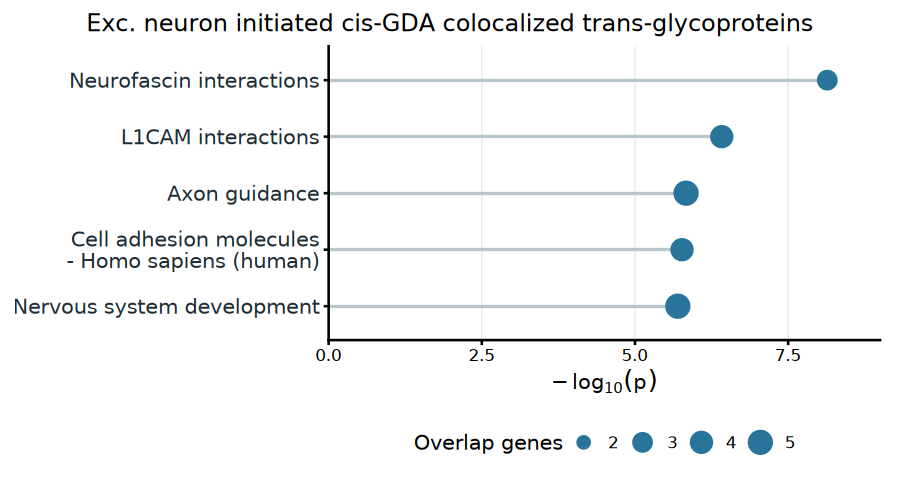

In [2]:
pw$label <- factor(pw$label, levels = rev(pw$label))

p <- ggplot(pw, aes(x = neglog10_p, y = label)) +
  geom_segment(aes(x = 0, xend = neglog10_p, yend = label), colour = "#B7C5CD", linewidth = 0.7) +
  geom_point(aes(size = overlap_n), colour = "#28749A") +
  scale_size_continuous(name = "Overlap genes", range = c(3, 6), breaks = 2:5, limits = c(2, 5)) +
  scale_x_continuous(limits = c(0, 9), expand = expansion(mult = c(0, 0))) +
  scale_y_discrete(labels = function(x) sub(" - Homo", "\n- Homo", x)) +
  labs(title = "Exc. neuron initiated cis-GDA colocalized trans-glycoproteins",
       x = expression(-log[10](italic(p))), y = NULL) +
  theme_classic(base_size = 12) +
  theme(plot.title = element_text(size = 14, hjust = 0.5), plot.title.position = "plot", plot.margin = margin(8, 12, 8, 12),
        axis.text.y = element_text(size = 12, colour = "#1F2D35"),
        panel.grid.major.x = element_line(colour = "#E6EBEE", linewidth = 0.3),
        legend.position = "bottom")

options(repr.plot.width = 7.5, repr.plot.height = 4)
p